# 08 - HDBSCAN

HDBSCAN adalah algoritma clustering berbasis kepadatan yang dapat menentukan jumlah klaster secara otomatis. Data yang tidak masuk klaster diberi label **-1 (noise)**.

Notebook ini memakai `X_scaled.csv` dari preprocessing yang sama dengan K-Means dan DBSCAN. Parameter dibuat sederhana agar mudah dipahami.

In [1]:
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

folder = 'Clustering_Stok'
X_df = pd.read_csv(f'{folder}/X_scaled.csv')
fitur = json.load(open(f'{folder}/meta.json'))['features']
X = X_df[fitur].values

print('Jumlah data  :', X.shape[0])
print('Jumlah fitur :', X.shape[1])
X_df.head()

Jumlah data  : 282
Jumlah fitur : 9


,Outlet,Item,mean_daily,max_daily,trend_weekly_pct,weekend_ratio,momentum_30d,share_morning,share_evening,loyalty_share,avg_price
0,SHOP001,Air Mineral,1.322714,0.672432,-0.974961,-0.109107,-0.461093,0.166549,0.793543,-1.130617,-2.680986
1,SHOP001,Americano (Hot Arabica),1.511247,1.625325,-0.227430,0.609017,0.319884,0.107841,-0.430186,-1.130617,-0.305002
2,SHOP001,Americano (Hot Houseblend),0.782254,1.625325,-0.045790,0.579206,-0.298570,0.727303,0.343123,-1.130617,-0.305002
3,SHOP001,Americano (Ice Arabica),1.234732,0.672432,-0.884758,0.891666,-0.662410,0.501842,-0.654609,-1.130617,-0.305002
4,SHOP001,Americano (Ice Houseblend),1.372989,0.672432,-0.628443,-0.213534,0.060751,0.818590,-0.933467,-1.130617,-0.305002


## 1. Jalankan HDBSCAN

- `min_cluster_size=5`: minimal anggota agar sebuah klaster dianggap valid.
- `min_samples=3`: tingkat kepadatan yang diperlukan; nilai lebih besar biasanya menghasilkan lebih banyak noise.
- Metrik jarak yang digunakan adalah Euclidean.

In [2]:
mulai = time.perf_counter()
model = HDBSCAN(min_cluster_size=5, min_samples=3, metric='euclidean', copy=True)
label = model.fit_predict(X)
waktu = time.perf_counter() - mulai

jumlah_klaster = len(set(label)) - (1 if -1 in label else 0)
noise = (label == -1).mean() * 100
ok = label != -1

print('Jumlah klaster :', jumlah_klaster)
print('Data noise     :', f'{noise:.2f}%')
print('Data masuk klaster:', int(ok.sum()), 'dari', len(label))
pd.Series(label).value_counts().sort_index().rename_axis('Label klaster').to_frame('Jumlah data')

Jumlah klaster : 4
Data noise     : 45.74%
Data masuk klaster: 153 dari 282


,Jumlah data
Label klaster,
-1,129
0,8
1,74
2,57
3,14


## 2. Evaluasi dan Simpan Hasil

Metrik evaluasi dihitung pada data yang bukan noise. Silhouette makin tinggi umumnya makin baik; Davies-Bouldin makin rendah umumnya makin baik.

In [3]:
sil = np.nan
db = np.nan
ch = np.nan
if jumlah_klaster >= 2 and ok.sum() > jumlah_klaster:
    sil = silhouette_score(X[ok], label[ok], metric='euclidean')
    db = davies_bouldin_score(X[ok], label[ok])
    ch = calinski_harabasz_score(X[ok], label[ok])

ringkasan = {
    'Model': 'HDBSCAN',
    'Algoritma': 'HDBSCAN',
    'Metrik': 'Euclidean (L2)',
    'Parameter': 'min_cluster_size=5, min_samples=3',
    'Jumlah Klaster': int(jumlah_klaster),
    'Noise (%)': round(float(noise), 2),
    'Silhouette (own)': round(float(sil), 4) if np.isfinite(sil) else np.nan,
    'Silhouette (Euclid)': round(float(sil), 4) if np.isfinite(sil) else np.nan,
    'Davies-Bouldin': round(float(db), 4) if np.isfinite(db) else np.nan,
    'Calinski-Harabasz': round(float(ch), 2) if np.isfinite(ch) else np.nan,
    'Waktu (s)': round(float(waktu), 5)
}

pd.DataFrame({'Outlet': X_df['Outlet'], 'Item': X_df['Item'], 'cluster': label}).to_csv(f'{folder}/labels_HDBSCAN.csv', index=False)
pd.DataFrame([ringkasan]).to_csv(f'{folder}/eval_HDBSCAN.csv', index=False)
pd.DataFrame([ringkasan]).T.rename(columns={0: 'Hasil'})

,Hasil
Model,HDBSCAN
Algoritma,HDBSCAN
Metrik,Euclidean (L2)
Parameter,"min_cluster_size=5, min_samples=3"
Jumlah Klaster,4
Noise (%),45.74
Silhouette (own),0.2173
Silhouette (Euclid),0.2173
Davies-Bouldin,1.4175
Calinski-Harabasz,32.39


## 3. Visualisasi Klaster

PCA mengubah fitur menjadi dua sumbu untuk keperluan gambar saja. Proses clustering tetap memakai seluruh fitur asli yang sudah distandarisasi.

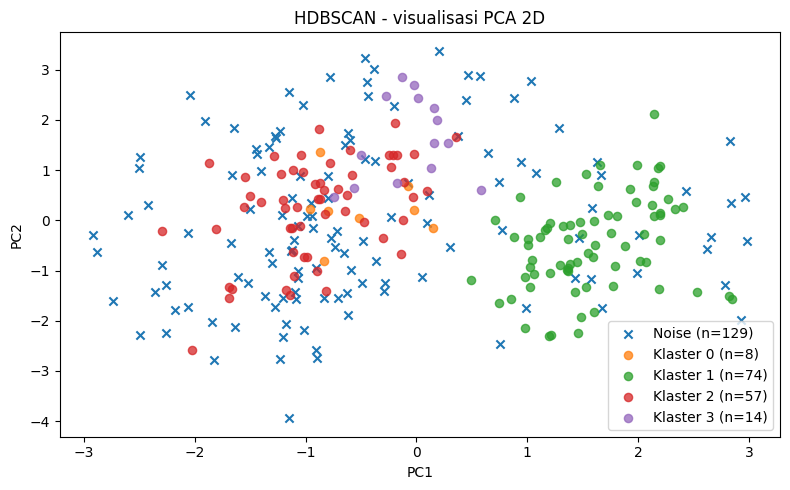

In [4]:
X_2d = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(8, 5))
for c in sorted(set(label)):
    pilih = label == c
    if c == -1:
        plt.scatter(X_2d[pilih, 0], X_2d[pilih, 1], marker='x', s=35, label=f'Noise (n={pilih.sum()})')
    else:
        plt.scatter(X_2d[pilih, 0], X_2d[pilih, 1], s=35, alpha=0.75, label=f'Klaster {c} (n={pilih.sum()})')
plt.title('HDBSCAN - visualisasi PCA 2D')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()

## Kesimpulan

HDBSCAN tidak perlu menentukan jumlah klaster di awal. Label `-1` berarti data dianggap noise, bukan klaster. Bandingkan hasilnya dengan K-Means dan DBSCAN menggunakan `07_Perbandingan.ipynb`; perhatikan juga persentase noise, bukan hanya nilai Silhouette.